# Day 003 — No-show rate by lead-time band and payer

**Business question:** Day 002 showed that in-person visits booked more than 14 days out no-show far more often. How steep is that curve across finer lead-time bands, how much do no-show rates differ by payer, and does the payer gap survive once lead time is held constant?

**Definition:** no-show rate = no-shows ÷ (completed + no-shows); cancellations are excluded. Lead time = visit date − booked date, in five bands (0–3, 4–7, 8–14, 15–28, 29+ days). Payer is the patient's payer on `dim_patient`, labelled from `dim_payer`.

All rows come from the seeded synthetic database in `shared/clinic.db`. They describe no real patients, providers, payers, or clinics.

In [1]:
from pathlib import Path
import sqlite3
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("../..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from shared.sqlutil import split_named_queries

DB = ROOT / "shared" / "clinic.db"
assert DB.exists(), f"Database not found: {DB}"
conn = sqlite3.connect(DB)

# Run the same named queries that run_all.py exports to results/.
queries = dict(split_named_queries(Path("query.sql").read_text(encoding="utf-8")))
q = {name: pd.read_sql(sql, conn) for name, sql in queries.items()}
sorted(q)

['by_lead_band',
 'by_payer',
 'in_person_by_lead_band',
 'overall',
 'payer_by_lead_band',
 'payer_join_check',
 'payer_observed_vs_expected',
 'payer_spread_by_lead_band']

## Data check and network rate

In [2]:
display(q["payer_join_check"])
display(q["overall"])

,scheduled_visits,no_patient_match,no_payer_match,duplicate_patients
0,49538,0,0,0


,eligible_visits,no_shows,no_show_rate_pct
0,45090,7898,17.5


## By lead-time band (all modalities, then in person only)

In [3]:
display(q["by_lead_band"])
display(q["in_person_by_lead_band"])

,lead_band,eligible_visits,no_shows,no_show_rate_pct,pct_of_eligible
0,1: 0-3 days,10726,1132,10.6,23.8
1,2: 4-7 days,9488,1231,13.0,21.0
2,3: 8-14 days,11414,2095,18.4,25.3
3,4: 15-28 days,12082,2963,24.5,26.8
4,5: 29+ days,1380,477,34.6,3.1


,lead_band,eligible_visits,no_shows,no_show_rate_pct
0,1: 0-3 days,6164,773,12.5
1,2: 4-7 days,4528,713,15.7
2,3: 8-14 days,8946,1764,19.7
3,4: 15-28 days,11690,2891,24.7
4,5: 29+ days,1380,477,34.6


## By payer

Average lead time and long-lead share are nearly the same for every payer, so the payer gap is not a booking-pattern artifact.

In [4]:
q["by_payer"]

,payer_id,payer_name,payer_type,eligible_visits,no_shows,no_show_rate_pct,avg_lead_days,pct_over_14_days
0,MCAID,Medicaid,medicaid,7639,1579,20.7,10.5,30.1
1,SELF,Self-pay,self_pay,2226,439,19.7,10.3,28.8
2,BRCH,Birch HMO,commercial,7382,1371,18.6,10.6,30.8
3,SUMP,Summit PPO,commercial,14695,2530,17.2,10.5,29.9
4,MEDCR,Medicare FFS,medicare,13148,1979,15.1,10.3,29.3


## Payer × lead-time band

In [5]:
display(q["payer_by_lead_band"].pivot(index="payer_name", columns="lead_band", values="no_show_rate_pct"))
display(q["payer_by_lead_band"].pivot(index="payer_name", columns="lead_band", values="eligible_visits"))
display(q["payer_spread_by_lead_band"])

lead_band,1: 0-3 days,2: 4-7 days,3: 8-14 days,4: 15-28 days,5: 29+ days
payer_name,,,,,
Birch HMO,11.1,13.8,19.6,25.7,35.3
Medicaid,13.0,16.1,21.5,28.4,35.6
Medicare FFS,8.5,10.3,15.4,22.4,34.2
Self-pay,13.5,16.8,19.0,26.4,38.9
Summit PPO,10.5,12.6,18.7,23.5,33.3


lead_band,1: 0-3 days,2: 4-7 days,3: 8-14 days,4: 15-28 days,5: 29+ days
payer_name,,,,,
Birch HMO,1746,1540,1826,2032,238
Medicaid,1772,1678,1890,2046,253
Medicare FFS,3160,2756,3379,3490,363
Self-pay,550,469,567,568,72
Summit PPO,3498,3045,3752,3946,454


,lead_band,lowest_payer,lowest_rate_pct,highest_payer,highest_rate_pct,spread_pp
0,1: 0-3 days,Medicare FFS,8.5,Self-pay,13.5,5.0
1,2: 4-7 days,Medicare FFS,10.3,Self-pay,16.8,6.5
2,3: 8-14 days,Medicare FFS,15.4,Medicaid,21.5,6.1
3,4: 15-28 days,Medicare FFS,22.4,Medicaid,28.4,6.1
4,5: 29+ days,Summit PPO,33.3,Self-pay,38.9,5.6


## Observed vs expected no-shows by payer

Expected = each payer's visits scored at the network no-show rate for their lead band and modality (indirect standardization).

In [6]:
q["payer_observed_vs_expected"]

,payer_id,payer_name,eligible_visits,observed_no_shows,expected_no_shows,observed_rate_pct,expected_rate_pct,observed_to_expected
0,MCAID,Medicaid,7639,1579,1340.5,20.7,17.5,1.18
1,SELF,Self-pay,2226,439,387.1,19.7,17.4,1.13
2,BRCH,Birch HMO,7382,1371,1300.5,18.6,17.6,1.05
3,SUMP,Summit PPO,14695,2530,2574.0,17.2,17.5,0.98
4,MEDCR,Medicare FFS,13148,1979,2296.0,15.1,17.5,0.86


## Chart

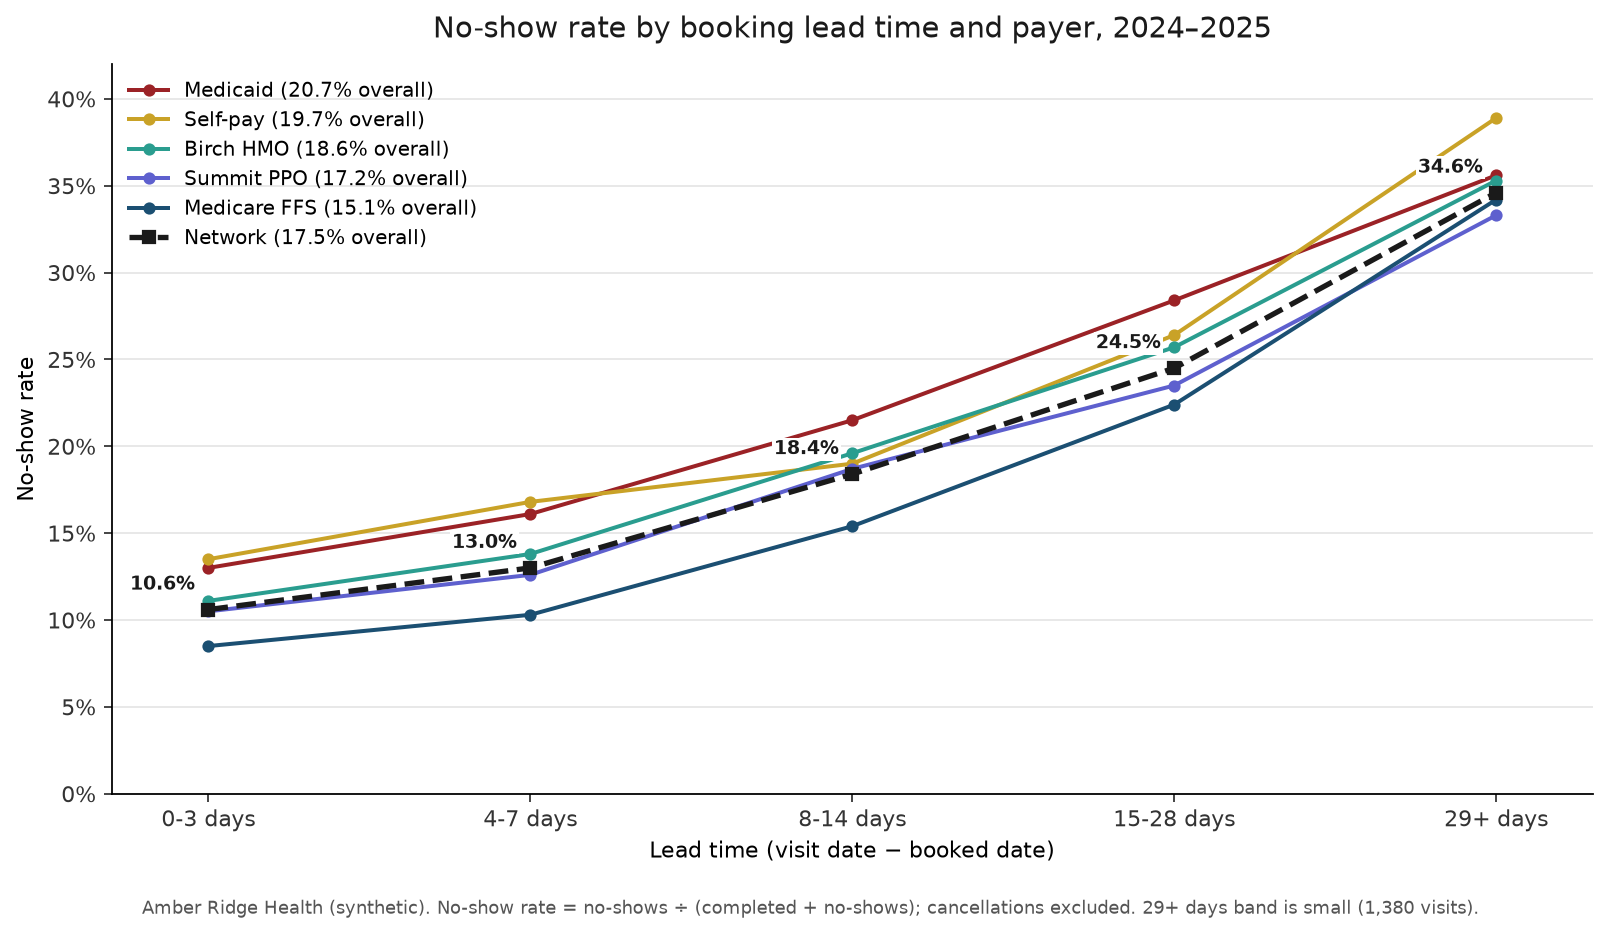

In [7]:
pb = q["payer_by_lead_band"].copy()
net = q["by_lead_band"].set_index("lead_band")
bands = net.index.tolist()
xlabels = [b.split(": ", 1)[1] for b in bands]
x = list(range(len(bands)))
payer_order = q["by_payer"]["payer_name"].tolist()  # highest overall rate first
colors = {"Medicaid": "#9b2226", "Self-pay": "#c9a227", "Birch HMO": "#2a9d8f",
          "Summit PPO": "#5e60ce", "Medicare FFS": "#1b4f72"}
overall_rate = q["by_payer"].set_index("payer_name")["no_show_rate_pct"]

fig, ax = plt.subplots(figsize=(10.4, 6.0), dpi=160)
for payer in payer_order:
    s = pb[pb["payer_name"] == payer].set_index("lead_band").loc[bands, "no_show_rate_pct"]
    ax.plot(x, s.values, marker="o", markersize=4.5, linewidth=1.8, color=colors[payer],
            label=f"{payer} ({overall_rate[payer]:.1f}% overall)")
ax.plot(x, net["no_show_rate_pct"].values, color="#1a1a1a", linestyle="--", linewidth=2.4,
        marker="s", markersize=5, label=f"Network ({q['overall'].iloc[0]['no_show_rate_pct']:.1f}% overall)", zorder=5)
for xi, v in zip(x, net["no_show_rate_pct"].values):
    ax.annotate(f"{v:.1f}%", xy=(xi, v), xytext=(-6, 9), textcoords="offset points",
                ha="right", fontsize=8.5, color="#1a1a1a", fontweight="bold",
                bbox=dict(boxstyle="square,pad=0.1", facecolor="white", edgecolor="none"))

ax.set_xticks(x)
ax.set_xticklabels(xlabels)
ax.set_xlim(-0.3, len(bands) - 0.7)
ax.set_ylim(0, 42)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _pos: f"{v:.0f}%"))
ax.set_xlabel("Lead time (visit date − booked date)")
ax.set_ylabel("No-show rate")
ax.set_title("No-show rate by booking lead time and payer, 2024–2025",
             fontsize=13, pad=12, color="#1a1a1a")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(colors="#333333")
ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(loc="upper left", frameon=False, fontsize=8.8)
fig.text(0.5, 0.015,
         "Amber Ridge Health (synthetic). No-show rate = no-shows ÷ (completed + no-shows); cancellations excluded. "
         "29+ days band is small (1,380 visits).",
         ha="center", fontsize=8, color="#555555")
fig.subplots_adjust(bottom=0.14, left=0.08, right=0.97, top=0.90)
fig.savefig("chart.png", facecolor="white")
plt.show()

## Takeaway

- Lead time is the stronger driver: the network no-show rate climbs from **10.6%** for visits booked 0–3 days out to **24.5%** at 15–28 days and **34.6%** at 29+ days. In-person visits alone follow the same curve (**12.5%** to **34.6%**).
- Payer matters, but less: **Medicaid 20.7%** and **Self-pay 19.7%** versus **Medicare FFS 15.1%**. Every payer has almost the same lead-time mix, and the gap holds inside each band (5.0 to 6.5 points), so it is not explained by booking patterns. Medicaid has **1.18×** the no-shows its lead-time and modality mix predicts; Medicare FFS has **0.86×**.
- The worst cells combine both: Medicaid visits booked 15–28 days out no-show at **28.4%**.

A clinic manager should shorten booking windows first (it moves every payer), then aim reminder calls and transportation help at Medicaid and self-pay patients whose visits are booked more than two weeks out.

In [8]:
conn.close()